# Windows-focused Cybersecurity Threat Intelligence Knowledge Graph

This notebook reproduces the final analysis from the published Turtle ontology. It uses integrated MITRE ATT&CK, NVD/CVE, and CWE data for Windows-focused cybersecurity analysis.

In [2]:
%pip install rdflib pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load the ontology and instance files

In [ ]:
from rdflib import Graph
import pandas as pd
import matplotlib.pyplot as plt

ontology_url = "https://raw.githubusercontent.com/Timoseee/windows-cyber-threat-kg/main/windows-cyber-threat-ontology.ttl"
instances_url = "https://raw.githubusercontent.com/Timoseee/windows-cyber-threat-kg/main/windows-cyber-threat-instances.ttl"
g = Graph()
g.parse(ontology_url, format="turtle")
g.parse(instances_url, format="turtle")
print(f"Loaded {len(g)} RDF triples.")

## 2. CVE analysis

This query lists each CVE, its severity, its CWE weakness, and the affected Windows products.

In [3]:
cve_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?cve_name ?severity_name ?weakness_name ?product_name
WHERE {
    ?cve a cti:Vulnerability;
         rdfs:label ?cve_name;
         cti:hasSeverity ?severity;
         cti:hasWeakness ?weakness;
         cti:affectsProduct ?product.

    ?severity rdfs:label ?severity_name.
    ?weakness rdfs:label ?weakness_name.
    ?product rdfs:label ?product_name.
}
ORDER BY ?cve_name ?product_name
"""

cve_rows = []
for row in g.query(cve_query):
    cve_rows.append({
        "CVE ID": str(row.cve_name),
        "Severity": str(row.severity_name),
        "Weakness": str(row.weakness_name),
        "Affected Windows product": str(row.product_name)
    })

cve_df = pd.DataFrame(cve_rows).drop_duplicates()
cve_df

,CVE ID,Severity,Weakness,Affected Windows product
0,CVE-2024-30051,HIGH severity,CWE-122: Heap-based Buffer Overflow,Windows 11 Version 23H2
1,CVE-2024-30051,HIGH severity,CWE-787,Windows 11 Version 23H2
2,CVE-2024-30051,HIGH severity,CWE-122: Heap-based Buffer Overflow,windows_10_1507 *
3,CVE-2024-30051,HIGH severity,CWE-787,windows_10_1507 *
4,CVE-2024-30051,HIGH severity,CWE-122: Heap-based Buffer Overflow,windows_10_1607 *
...,...,...,...,...
60,CVE-2024-38080,HIGH severity,CWE-190,windows_11_21h2 *
61,CVE-2024-38080,HIGH severity,CWE-190,windows_11_22h2 *
62,CVE-2024-38080,HIGH severity,CWE-190,windows_11_23h2 *
63,CVE-2024-38080,HIGH severity,CWE-190,windows_server_2022 *


In [4]:
summary = (cve_df.groupby(["CVE ID", "Severity"])["Affected Windows product"].nunique().reset_index(name="Affected product count"))
summary

,CVE ID,Severity,Affected product count
0,CVE-2024-30051,HIGH severity,12
1,CVE-2024-30078,HIGH severity,17
2,CVE-2024-38063,CRITICAL severity,18
3,CVE-2024-38080,HIGH severity,6


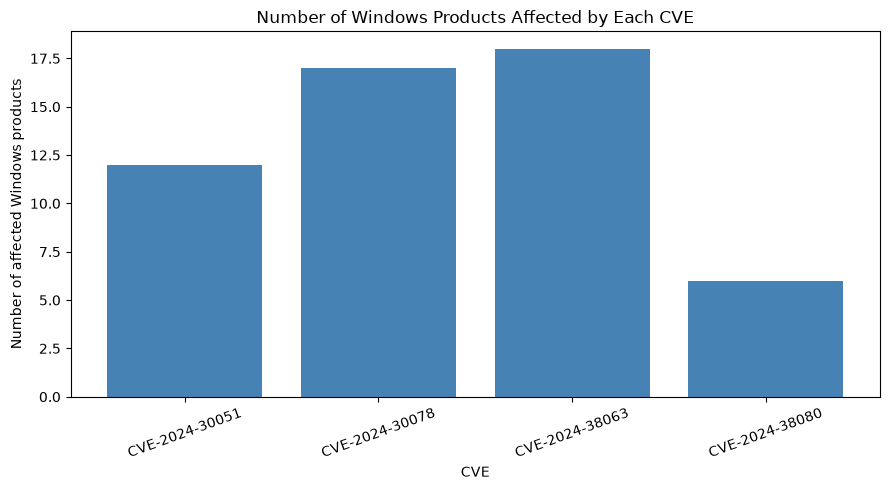

In [5]:
plt.close("all")
plt.figure(figsize=(9, 5))

x = range(len(summary))
plt.bar(x, summary["Affected product count"], color="steelblue")
plt.xticks(x, summary["CVE ID"], rotation=20)
plt.title("Number of Windows Products Affected by Each CVE")
plt.xlabel("CVE")
plt.ylabel("Number of affected Windows products")
plt.tight_layout()
plt.show()

## 3. ATT&CK technique analysis

This query counts the number of different threat actors associated with each selected Windows ATT&CK technique.

In [6]:
technique_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?technique_name (COUNT(DISTINCT ?actor) AS ?actor_count)
WHERE {
    ?actor a cti:ThreatActor ;
           cti:usesTechnique ?technique .

    ?technique rdfs:label ?technique_name .
}
GROUP BY ?technique_name
ORDER BY DESC(?actor_count)
"""

technique_rows = []
for row in g.query(technique_query):
    technique_rows.append({
        "Technique": str(row.technique_name),
        "Actor count": int(row.actor_count)
    })

technique_df = pd.DataFrame(technique_rows)
technique_df

,Technique,Actor count
0,Windows Command Shell (T1059.003),7
1,Spearphishing Attachment (T1566.001),6
2,PowerShell (T1059.001),6
3,Scheduled Task (T1053.005),5
4,Windows Management Instrumentation (T1047),3


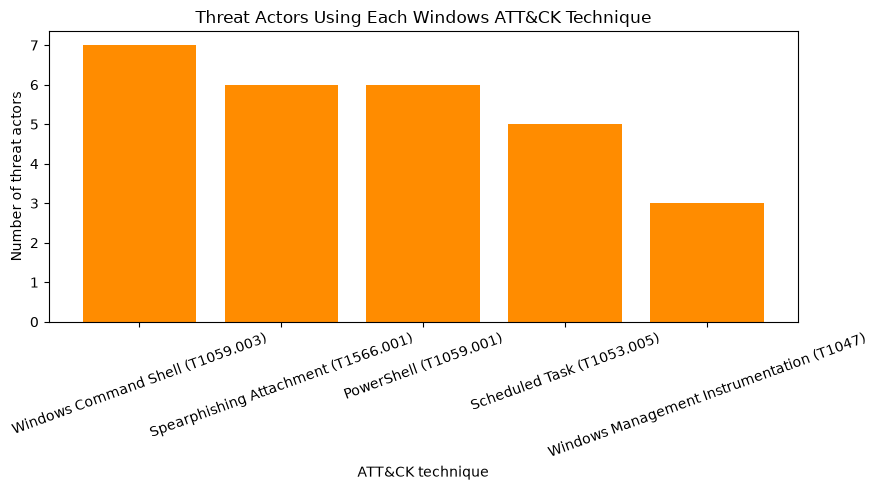

In [7]:
plt.close("all")
plt.figure(figsize=(9, 5))

x = range(len(technique_df))
plt.bar(x, technique_df["Actor count"], color="darkorange")
plt.xticks(x, technique_df["Technique"], rotation=20)
plt.title("Threat Actors Using Each Windows ATT&CK Technique")
plt.xlabel("ATT&CK technique")
plt.ylabel("Number of threat actors")
plt.tight_layout()
plt.show()

## 4. Cross-source Windows context

This query shows Windows-related threat actors, techniques, CVEs, and severities in one result table. It does not state that an actor directly exploits a particular CVE.

In [8]:
integration_query = """
PREFIX cti: <https://github.com/Timoseee/windows-cyber-threat-kg/ontology#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?actor_name ?technique_name ?cve_name ?severity_name
WHERE {
    ?actor a cti:ThreatActor ;
           rdfs:label ?actor_name ;
           cti:usesTechnique ?technique .
    ?technique rdfs:label ?technique_name ;
               cti:applicableToPlatform cti:Windows .
    ?cve a cti:Vulnerability ;
         rdfs:label ?cve_name ;
         cti:hasSeverity ?severity ;
         cti:affectsProduct ?product .
    ?severity rdfs:label ?severity_name .
    ?product cti:belongsToPlatform cti:Windows .
}
LIMIT 20
"""

integration_rows = []
for row in g.query(integration_query):
    integration_rows.append({
        "Threat actor": str(row.actor_name),
        "Technique": str(row.technique_name),
        "CVE": str(row.cve_name),
        "Severity": str(row.severity_name)
    })

integration_df = pd.DataFrame(integration_rows).drop_duplicates()
integration_df

,Threat actor,Technique,CVE,Severity
0,APT29 (G0016),Spearphishing Attachment (T1566.001),CVE-2024-30051,HIGH severity
1,APT3 (G0022),Scheduled Task (T1053.005),CVE-2024-30051,HIGH severity
2,APT3 (G0022),PowerShell (T1059.001),CVE-2024-30051,HIGH severity
3,APT3 (G0022),Windows Command Shell (T1059.003),CVE-2024-30051,HIGH severity
4,Elderwood (G0066),Spearphishing Attachment (T1566.001),CVE-2024-30051,HIGH severity
5,APT38 (G0082),Scheduled Task (T1053.005),CVE-2024-30051,HIGH severity
6,APT38 (G0082),PowerShell (T1059.001),CVE-2024-30051,HIGH severity
7,APT38 (G0082),Spearphishing Attachment (T1566.001),CVE-2024-30051,HIGH severity
8,APT38 (G0082),Windows Command Shell (T1059.003),CVE-2024-30051,HIGH severity
9,GALLIUM (G0093),Windows Management Instrumentation (T1047),CVE-2024-30051,HIGH severity
